# Sistemas de Ecuaciones Lineales: Interpretación Geométrica y Algebraica

## De ℝ² a ℝⁿ: Teoría, Visualizaciones y Aplicaciones

---

**Objetivo:** Desarrollar una comprensión completa y formal de cómo los sistemas de ecuaciones lineales pueden interpretarse geométricamente como intersecciones de rectas, planos e hiperplanos.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from sympy import symbols, Matrix, Eq, solve, linsolve
import plotly.graph_objects as go
import plotly.express as px
from ipywidgets import interact, FloatSlider
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 7)
print('✓ Librerías cargadas')

✓ Librerías cargadas


# 1. Introducción: Sistemas de Ecuaciones Lineales

## Definición Formal

Un **sistema de ecuaciones lineales** es una colección de $m$ ecuaciones con $n$ incógnitas:

$$\begin{cases}
a_{11}x_1 + a_{12}x_2 + \cdots + a_{1n}x_n = b_1 \\
a_{21}x_1 + a_{22}x_2 + \cdots + a_{2n}x_n = b_2 \\
\vdots \\
a_{m1}x_1 + a_{m2}x_2 + \cdots + a_{mn}x_n = b_m
\end{cases}$$

## Interpretación Geométrica

- **En ℝ²**: cada ecuación es una **recta**
- **En ℝ³**: cada ecuación es un **plano**
- **En ℝⁿ**: cada ecuación es un **hiperplano** de dimensión n-1

Resolver el sistema = encontrar la **intersección** de todos estos objetos geométricos.


# 2. Visualizacion de Sistemas de Ecuaciones

## 2a. Sistemas en 2D




### Gráfico Rectas

In [ ]:
def graficar_rectas_2d(a1, b1, c1, a2, b2, c2, titulo="Sistema 2D"):
    fig, ax = plt.subplots(figsize=(9, 8))
    x = np.linspace(-2, 8, 200)

    # Primera recta
    if abs(b1) > 1e-10:
        y1 = (c1 - a1 * x) / b1
        ax.plot(x, y1, 'b-', label=f'${a1:.1f}x + {b1:.1f}y = {c1:.1f}$', linewidth=2.5)

    # Segunda recta
    if abs(b2) > 1e-10:
        y2 = (c2 - a2 * x) / b2
        ax.plot(x, y2, 'r-', label=f'${a2:.1f}x + {b2:.1f}y = {c2:.1f}$', linewidth=2.5)

    # Buscar solución con SymPy
    x_sym, y_sym = sp.symbols('x y', real=True)
    eq1 = Eq(a1*x_sym + b1*y_sym, c1)
    eq2 = Eq(a2*x_sym + b2*y_sym, c2)

    try:
        sol = solve((eq1, eq2), (x_sym, y_sym))
        if sol:
            x_s, y_s = float(sol[x_sym]), float(sol[y_sym])
            ax.plot(x_s, y_s, 'go', markersize=12, label=f'Solución: ({x_s:.2f}, {y_s:.2f})', zorder=5)
    except:
        pass

    ax.grid(True, alpha=0.3)
    ax.set_xlim(-2, 8)
    ax.set_ylim(-2, 8)
    ax.set_xlabel('x', fontsize=12, fontweight='bold')
    ax.set_ylabel('y', fontsize=12, fontweight='bold')
    ax.set_title(titulo, fontsize=13, fontweight='bold')
    ax.legend(fontsize=10)
    ax.axhline(y=0, color='k', linewidth=0.5)
    ax.axvline(x=0, color='k', linewidth=0.5)
    plt.tight_layout()
    plt.show()

### Caso A: Solución Única (Rectas que se cortan)

Sistema:

$$
2x + y = 5 \\
x - y = 1
$$

Caso A: 2x + y = 5, x - y = 1


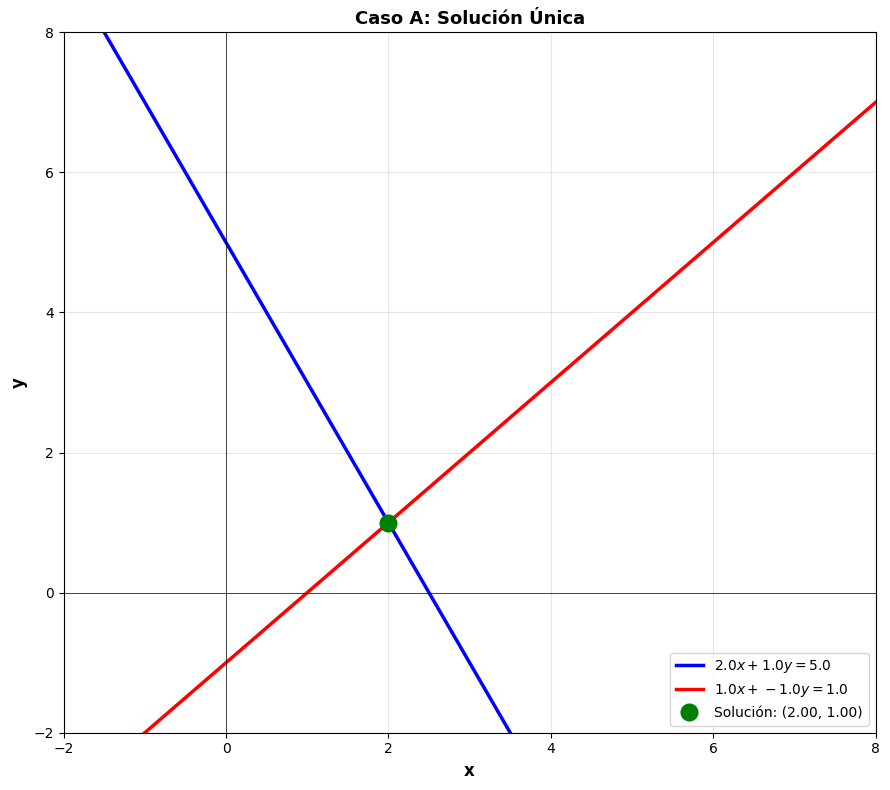

det(A) = -3.0000 (≠ 0 ⟹ solución única)
Solución: x = 2, y = 1


In [5]:
# Caso A: Solución única
print('Caso A: 2x + y = 5, x - y = 1')
graficar_rectas_2d(a1=2, b1=1, c1=5, a2=1, b2=-1, c2=1, titulo='Caso A: Solución Única')

# Calcular determinante
A = np.array([[2, 1], [1, -1]], dtype=float)
det = np.linalg.det(A)
print(f'det(A) = {det:.4f} (≠ 0 ⟹ solución única)')
print(f'Solución: x = 2, y = 1')

### Caso B: Sin Solución (Rectas Paralelas Distintas)

Sistema:
$$
2x + y = 5 \\
2x + y = 8
$$


Caso B: 2x + y = 5, 2x + y = 8


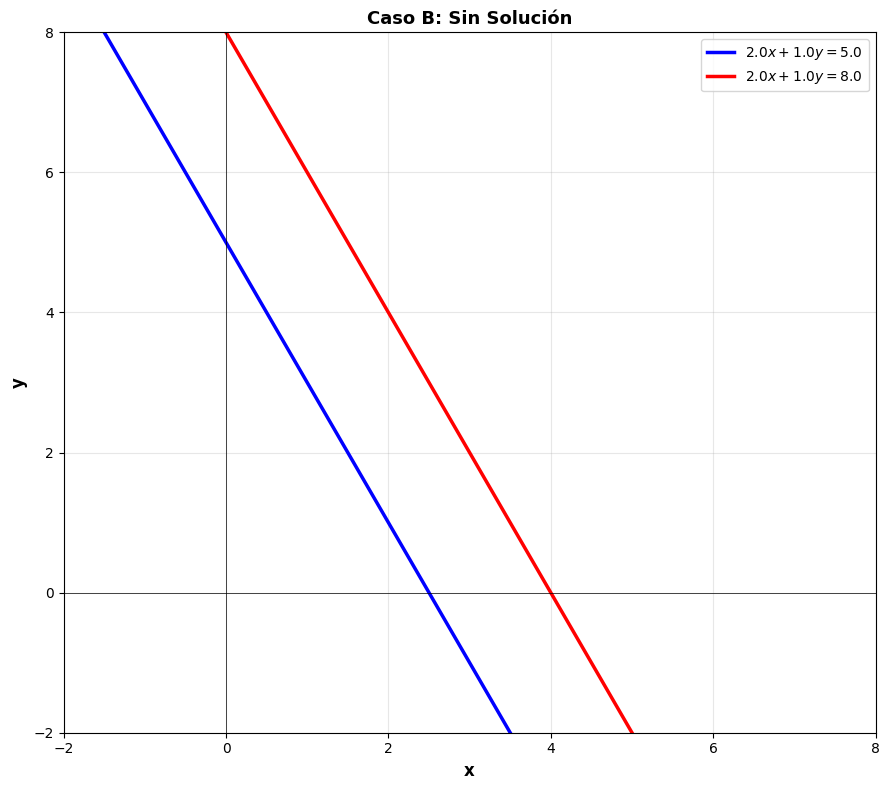

det(A) = 0.0000 (= 0, pero términos independientes distintos)
Las rectas son paralelas distintas: SIN SOLUCIÓN


In [4]:
print('Caso B: 2x + y = 5, 2x + y = 8')
graficar_rectas_2d(a1=2, b1=1, c1=5, a2=2, b2=1, c2=8, titulo='Caso B: Sin Solución')

A = np.array([[2, 1], [2, 1]], dtype=float)
det = np.linalg.det(A)
print(f'det(A) = {det:.4f} (= 0, pero términos independientes distintos)')
print(f'Las rectas son paralelas distintas: SIN SOLUCIÓN')

### Caso C: Infinitas Soluciones (Rectas Coincidentes)

Sistema:
$$
2x + y = 5 \\
4x + 2y = 10
$$

Caso C: 2x + y = 5, 4x + 2y = 10


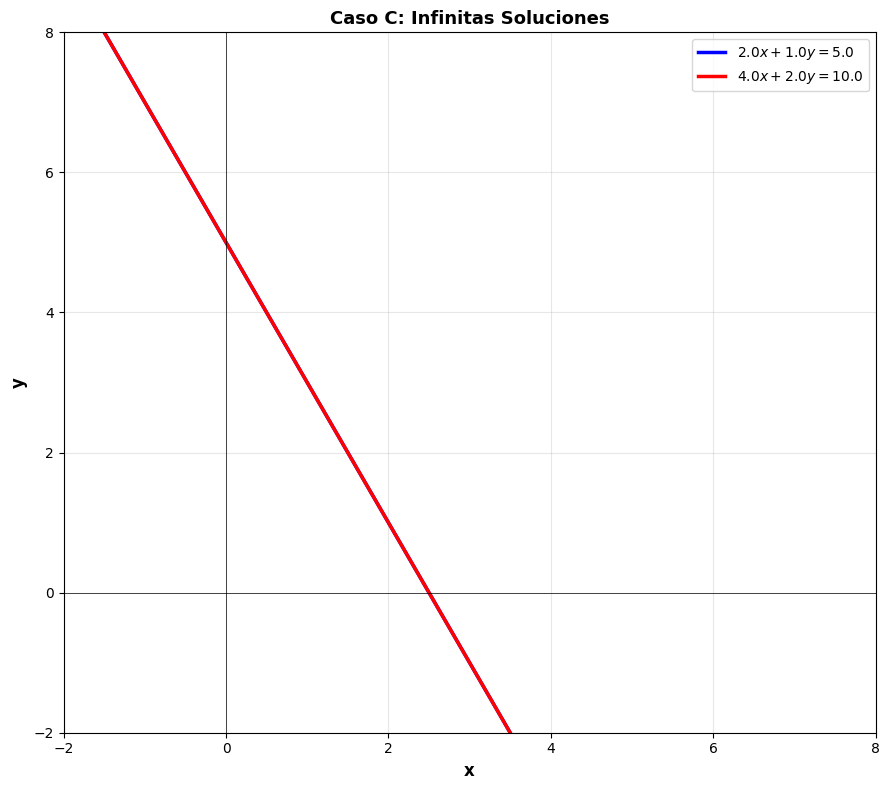

La segunda ecuación es el doble de la primera
Las rectas son IDÉNTICAS: INFINITAS SOLUCIONES


In [6]:
print('Caso C: 2x + y = 5, 4x + 2y = 10')
graficar_rectas_2d(a1=2, b1=1, c1=5, a2=4, b2=2, c2=10, titulo='Caso C: Infinitas Soluciones')
print(f'La segunda ecuación es el doble de la primera')
print(f'Las rectas son IDÉNTICAS: INFINITAS SOLUCIONES')

## 2b: Sistemas en 3D

### Gráficos Planos

In [38]:
# 1) GEOMETRÍA DEL PLANO RECORTADO POR LA CAJA
def interseccion_plano_caja(a, b, c, d, xlim, ylim, zlim, tol=1e-9):
    """
    Devuelve los puntos de intersección entre el plano
    ax + by + cz = d
    y la caja [xlim] x [ylim] x [zlim].
    """
    xmin, xmax = xlim
    ymin, ymax = ylim
    zmin, zmax = zlim

    V = np.array([
        [xmin, ymin, zmin],
        [xmin, ymin, zmax],
        [xmin, ymax, zmin],
        [xmin, ymax, zmax],
        [xmax, ymin, zmin],
        [xmax, ymin, zmax],
        [xmax, ymax, zmin],
        [xmax, ymax, zmax],
    ], dtype=float)

    edges = [
        (0,1), (0,2), (0,4),
        (1,3), (1,5),
        (2,3), (2,6),
        (3,7),
        (4,5), (4,6),
        (5,7),
        (6,7)
    ]

    puntos = []

    for i, j in edges:
        p1 = V[i]
        p2 = V[j]

        f1 = a*p1[0] + b*p1[1] + c*p1[2] - d
        f2 = a*p2[0] + b*p2[1] + c*p2[2] - d

        if abs(f1) < tol and abs(f2) < tol:
            puntos.append(tuple(p1))
            puntos.append(tuple(p2))
            continue

        if abs(f1) < tol:
            puntos.append(tuple(p1))
        if abs(f2) < tol:
            puntos.append(tuple(p2))

        if f1 * f2 < 0:
            t = f1 / (f1 - f2)
            p = p1 + t * (p2 - p1)
            puntos.append(tuple(p))

    puntos_unicos = []
    for p in puntos:
        p = np.array(p)
        if not any(np.allclose(p, q, atol=1e-7) for q in puntos_unicos):
            puntos_unicos.append(p)

    if len(puntos_unicos) < 3:
        return None

    return np.array(puntos_unicos)


def ordenar_puntos_poligono_3d(points, normal):
    """
    Ordena puntos coplanares alrededor del centroide.
    """
    centroid = points.mean(axis=0)
    normal = np.array(normal, dtype=float)
    normal = normal / np.linalg.norm(normal)

    ref = points[0] - centroid
    if np.linalg.norm(ref) < 1e-12 and len(points) > 1:
        ref = points[1] - centroid
    u = ref / np.linalg.norm(ref)

    v = np.cross(normal, u)
    v = v / np.linalg.norm(v)

    angulos = []
    for p in points:
        w = p - centroid
        px = np.dot(w, u)
        py = np.dot(w, v)
        angulos.append(np.arctan2(py, px))

    idx = np.argsort(angulos)
    return points[idx]


def agregar_plano_recortado(fig, a, b, c, d, color, xlim, ylim, zlim, nombre):
    puntos = interseccion_plano_caja(a, b, c, d, xlim, ylim, zlim)
    if puntos is None:
        return

    puntos = ordenar_puntos_poligono_3d(puntos, normal=[a, b, c])

    x = puntos[:, 0]
    y = puntos[:, 1]
    z = puntos[:, 2]

    i, j, k = [], [], []
    for t in range(1, len(puntos) - 1):
        i.append(0)
        j.append(t)
        k.append(t + 1)

    fig.add_trace(go.Mesh3d(
        x=x, y=y, z=z,
        i=i, j=j, k=k,
        color=color,
        opacity=0.55,
        name=nombre,
        flatshading=True,
        hoverinfo='name'
    ))


# 2) INTERSECCIÓN DE DOS PLANOS = RECTA
def interseccion_dos_planos(pl1, pl2, tol=1e-10):
    """
    Devuelve:
      - ('linea', p0, v) si se intersectan en una recta
      - ('coincidentes', None, None) si son el mismo plano
      - ('paralelos', None, None) si son paralelos distintos
    """
    a1, b1, c1, d1 = pl1
    a2, b2, c2, d2 = pl2

    n1 = np.array([a1, b1, c1], dtype=float)
    n2 = np.array([a2, b2, c2], dtype=float)

    v = np.cross(n1, n2)

    if np.linalg.norm(v) < tol:
        # Planos paralelos o coincidentes
        M = np.vstack([n1, n2])
        if np.linalg.matrix_rank(M, tol) == 1:
            # Revisar consistencia con d
            ratios = []
            for x, y in zip(n1, n2):
                if abs(y) > tol:
                    ratios.append(x / y)

            # Forma más robusta: rango aumentado
            A = np.array([[a1, b1, c1],
                          [a2, b2, c2]], dtype=float)
            B = np.array([d1, d2], dtype=float)

            if np.linalg.matrix_rank(A, tol) == np.linalg.matrix_rank(np.column_stack([A, B]), tol):
                return ('coincidentes', None, None)
            else:
                return ('paralelos', None, None)

        return ('paralelos', None, None)

    # Punto particular de la recta: solución de mínimo norma de A x = d
    A = np.array([[a1, b1, c1],
                  [a2, b2, c2]], dtype=float)
    d = np.array([d1, d2], dtype=float)

    p0, *_ = np.linalg.lstsq(A, d, rcond=None)

    return ('linea', p0, v)


def recortar_recta_a_caja(p0, v, xlim, ylim, zlim, tol=1e-12):
    """
    Recorta la recta x = p0 + t v a la caja.
    Devuelve dos puntos extremos si corta la caja.
    """
    bounds = [xlim, ylim, zlim]
    tmin, tmax = -np.inf, np.inf

    for i in range(3):
        if abs(v[i]) < tol:
            if p0[i] < bounds[i][0] or p0[i] > bounds[i][1]:
                return None
        else:
            t1 = (bounds[i][0] - p0[i]) / v[i]
            t2 = (bounds[i][1] - p0[i]) / v[i]
            ta, tb = min(t1, t2), max(t1, t2)
            tmin = max(tmin, ta)
            tmax = min(tmax, tb)

            if tmin > tmax:
                return None

    P1 = p0 + tmin * v
    P2 = p0 + tmax * v
    return P1, P2


def agregar_recta_solucion(fig, p0, v, xlim, ylim, zlim, nombre="Recta solución"):
    segmento = recortar_recta_a_caja(p0, v, xlim, ylim, zlim)
    if segmento is None:
        return False

    P1, P2 = segmento

    fig.add_trace(go.Scatter3d(
        x=[P1[0], P2[0]],
        y=[P1[1], P2[1]],
        z=[P1[2], P2[2]],
        mode='lines',
        line=dict(color='black', width=8),
        name=nombre
    ))
    return True


# 3) INTERSECCIÓN DE TRES PLANOS
def resolver_tres_planos(planos, tol=1e-10):
    """
    Devuelve:
      - ('punto', p) si hay solución única
      - ('linea', p0, v) si la intersección común es una recta
      - ('infinitas', None) si hay infinitas soluciones pero no se parametriza aquí
      - ('sin_solucion', None) si no hay solución común
    """
    A = np.array([[p[0], p[1], p[2]] for p in planos], dtype=float)
    d = np.array([p[3] for p in planos], dtype=float)

    rankA = np.linalg.matrix_rank(A, tol)
    rankAug = np.linalg.matrix_rank(np.column_stack([A, d]), tol)

    if rankA < rankAug:
        return ('sin_solucion', None)

    if rankA == 3:
        p = np.linalg.solve(A, d)
        return ('punto', p)

    if rankA == 2:
        # La intersección común puede ser una recta
        # Tomamos dos planos independientes
        idxs = None
        for i in range(3):
            for j in range(i+1, 3):
                M = np.array([
                    [planos[i][0], planos[i][1], planos[i][2]],
                    [planos[j][0], planos[j][1], planos[j][2]]
                ], dtype=float)
                if np.linalg.matrix_rank(M, tol) == 2:
                    idxs = (i, j)
                    break
            if idxs is not None:
                break

        if idxs is not None:
            tipo, p0, v = interseccion_dos_planos(planos[idxs[0]], planos[idxs[1]], tol=tol)
            if tipo == 'linea':
                # Verificar que la recta también satisface el tercer plano
                a, b, c, dd = planos[3 - idxs[0] - idxs[1]]
                if abs(a*p0[0] + b*p0[1] + c*p0[2] - dd) < 1e-7 and abs(a*v[0] + b*v[1] + c*v[2]) < 1e-7:
                    return ('linea', p0, v)

        return ('infinitas', None)

    if rankA == 1:
        return ('infinitas', None)

    return ('sin_solucion', None)


def agregar_punto_solucion(fig, p, nombre="Punto solución"):
    fig.add_trace(go.Scatter3d(
        x=[p[0]],
        y=[p[1]],
        z=[p[2]],
        mode='markers+text',
        marker=dict(size=8, color='black'),
        text=[f"({p[0]:.2f}, {p[1]:.2f}, {p[2]:.2f})"],
        textposition='top center',
        name=nombre
    ))


# 4) FUNCIÓN PRINCIPAL
def graficar_planos_3d(ecuaciones, titulo="Intersección de Planos"):
    """
    Grafica planos recortados y muestra la solución del sistema:
    - 2 planos -> recta solución si existe
    - 3 planos -> punto solución si existe, o recta común si aplica
    """
    fig = go.Figure()

    xlim = (-10, 10)
    ylim = (-10, 10)
    zlim = (-8, 8)

    colores = ['blue', 'red', 'green', 'orange', 'purple', 'brown']

    # Dibujar planos
    for idx, (a, b, c, d) in enumerate(ecuaciones):
        agregar_plano_recortado(
            fig,
            a, b, c, d,
            color=colores[idx % len(colores)],
            xlim=xlim, ylim=ylim, zlim=zlim,
            nombre=f'{a:.1f}x + {b:.1f}y + {c:.1f}z = {d:.1f}'
        )

    mensaje_solucion = ""

    # Mostrar solución según el número de planos
    if len(ecuaciones) == 2:
        tipo, p0, v = interseccion_dos_planos(ecuaciones[0], ecuaciones[1])

        if tipo == 'linea':
            agregar_recta_solucion(fig, p0, v, xlim, ylim, zlim, nombre="Recta solución")
            mensaje_solucion = (
                f"Solución: recta de intersección\n"
                f"Punto base ≈ ({p0[0]:.3f}, {p0[1]:.3f}, {p0[2]:.3f})\n"
                f"Dirección ≈ ({v[0]:.3f}, {v[1]:.3f}, {v[2]:.3f})"
            )
        elif tipo == 'paralelos':
            mensaje_solucion = "Solución: no existe intersección (planos paralelos)"
        elif tipo == 'coincidentes':
            mensaje_solucion = "Solución: infinitas soluciones (planos coincidentes)"

    elif len(ecuaciones) == 3:
        resultado = resolver_tres_planos(ecuaciones)

        if resultado[0] == 'punto':
            p = resultado[1]
            agregar_punto_solucion(fig, p, nombre="Punto solución")
            mensaje_solucion = f"Solución única: ({p[0]:.3f}, {p[1]:.3f}, {p[2]:.3f})"

        elif resultado[0] == 'linea':
            _, p0, v = resultado
            agregar_recta_solucion(fig, p0, v, xlim, ylim, zlim, nombre="Recta solución común")
            mensaje_solucion = (
                f"Infinitas soluciones: recta común\n"
                f"Punto base ≈ ({p0[0]:.3f}, {p0[1]:.3f}, {p0[2]:.3f})\n"
                f"Dirección ≈ ({v[0]:.3f}, {v[1]:.3f}, {v[2]:.3f})"
            )

        elif resultado[0] == 'infinitas':
            mensaje_solucion = "Infinitas soluciones"
        elif resultado[0] == 'sin_solucion':
            mensaje_solucion = "No existe solución común"

    else:
        mensaje_solucion = "Visualización generada"

    fig.update_layout(
        title=f"{titulo}<br><sup>{mensaje_solucion}</sup>",
        scene=dict(
            xaxis=dict(title="x", range=list(xlim)),
            yaxis=dict(title="y", range=list(ylim)),
            zaxis=dict(title="z", range=list(zlim)),
            camera=dict(eye=dict(x=1.5, y=1.5, z=1.3))
        ),
        width=950,
        height=780,
        showlegend=True
    )

    fig.show()

### Caso A: Solución Única (Planos que se cortan)

Sistema:

$$
x + y + z = 1 \\
x - y + z = 0 \\
2x + y - z = 1
$$

In [40]:
# Caso A: Solución Única
print('='*80)
print('Caso A: Tres Planos Cortándose en un PUNTO')
print('='*80)
print()
print('Sistema:')
print('  x + y + z = 1')
print('  x - y + z = 0')
print('  2x + y - z = 1')
print()

A = np.array([[1, 1, 1],
              [1, -1, 1],
              [2, 1, -1]], dtype=float)
b = np.array([1, 0, 1], dtype=float)

A_sym = sp.Matrix(A)
b_sym = sp.Matrix(b)

print(f'rank(A) = {A_sym.rank()}')
print(f'det(A) = {float(A_sym.det()):.4f}')
print()

sol = np.linalg.solve(A, b)
print(f'SOLUCIÓN ÚNICA: x = {sol[0]:.4f}, y = {sol[1]:.4f}, z = {sol[2]:.4f}')
print()

print('Gráfico de los tres planos:')
graficar_planos_3d([(1, 1, 1, 1), (1, -1, 1, 0), (2, 1, -1, 1)],
                    'Caso A: Tres Planos → Punto')

Caso A: Tres Planos Cortándose en un PUNTO

Sistema:
  x + y + z = 1
  x - y + z = 0
  2x + y - z = 1

rank(A) = 3
det(A) = 6.0000

SOLUCIÓN ÚNICA: x = 0.3333, y = 0.5000, z = 0.1667

Gráfico de los tres planos:


### Caso B: Infinitas Soluciones

Sistema:

$$
x + y + z = 1 \\
x - y + z = 0 \\
$$

In [41]:
print(),
print('='*80)
print('Caso B: Dos Planos Cortándose en una RECTA')
print('='*80)
print()
print('Sistema:')
print('  x + y + z = 1')
print('  x - y + z = 0')
print()

A = np.array([[1, 1, 1],
              [1, -1, 1]], dtype=float)
b = np.array([1, 0], dtype=float)

A_sym = sp.Matrix(A)
b_sym = sp.Matrix(b)

print(f'rank(A) = {A_sym.rank()}')
print(f'nulidad(A) = {3 - A_sym.rank()}')
print()

print('El espacio solución es una RECTA (1 parámetro libre)')
print()

# Resolver simbólicamente
x, y, z = sp.symbols('x y z')
eq1 = sp.Eq(x + y + z, 1)
eq2 = sp.Eq(x - y + z, 0)

sol_dict = sp.solve([eq1, eq2], [x, y])
print(f'Solución parametrizada:')
print(f'  x = {sol_dict[x]}')
print(f'  y = {sol_dict[y]}')
print(f'  z = z (parámetro libre)')
print()

print('Interpretación geométrica:')
print('  Los dos planos se cortan en una RECTA')
print('  La recta está parametrizada por z')
print()

print('Gráfico de los dos planos:')
graficar_planos_3d([(1, 1, 1, 1), (1, -1, 1, 0)],
                    'Caso B: Dos Planos → Recta')


Caso B: Dos Planos Cortándose en una RECTA

Sistema:
  x + y + z = 1
  x - y + z = 0

rank(A) = 2
nulidad(A) = 1

El espacio solución es una RECTA (1 parámetro libre)

Solución parametrizada:
  x = 1/2 - z
  y = 1/2
  z = z (parámetro libre)

Interpretación geométrica:
  Los dos planos se cortan en una RECTA
  La recta está parametrizada por z

Gráfico de los dos planos:


### Caso C: Sin Soluciones

Sistema:

$$
x + y + z = 1 \\
x + y + z = 4 \\
x + y + z = 7 \\
$$

In [43]:
print(),
print('='*80)
print('Caso C: Planos PARALELOS DISTINTOS (Sin Solución)')
print('='*80)
print()
print('Sistema:')
print('  x + y + z = 1')
print('  x + y + z = 4')
print('  x + y + z = 7')
print()

A = np.array([[1, 1, 1],
              [1, 1, 1],
              [1, 1, 1]], dtype=float)
b = np.array([1, 4, 7], dtype=float)

A_sym = sp.Matrix(A)
b_sym = sp.Matrix(b)
Ab_sym = A_sym.row_join(b_sym)

print(f'rank(A) = {A_sym.rank()}')
print(f'rank([A|b]) = {Ab_sym.rank()}')
print()

print('rank(A) < rank([A|b]) ⟹ SISTEMA INCOMPATIBLE')
print()

print('¿Por qué? Los vectores normales de los planos son proporcionales:')
print('  Plano 1: normal = (1, 1, 1)')
print('  Plano 2: normal = (1, 1, 1) (igual)')
print('  ⟹ Los planos son PARALELOS')
print()
print('Pero los términos independientes son distintos (1 ≠ 2)')
print('  ⟹ Los planos son PARALELOS DISTINTOS → NO INTERSECTAN')
print()

print('Gráfico de los dos planos paralelos:')
graficar_planos_3d([(1, 1, 1, 1), (1, 1, 1, 4), (1, 1, 1, 7)],
                    'Caso C: Planos Paralelos Distintos (Sin Solución)')


Caso C: Planos PARALELOS DISTINTOS (Sin Solución)

Sistema:
  x + y + z = 1
  x + y + z = 4
  x + y + z = 7

rank(A) = 1
rank([A|b]) = 2

rank(A) < rank([A|b]) ⟹ SISTEMA INCOMPATIBLE

¿Por qué? Los vectores normales de los planos son proporcionales:
  Plano 1: normal = (1, 1, 1)
  Plano 2: normal = (1, 1, 1) (igual)
  ⟹ Los planos son PARALELOS

Pero los términos independientes son distintos (1 ≠ 2)
  ⟹ Los planos son PARALELOS DISTINTOS → NO INTERSECTAN

Gráfico de los dos planos paralelos:


# 3. Teorema de Rouché-Capelli

## Clasificación Completa de Sistemas

Dado el sistema $Ax = b$ donde $A \in \mathbb{R}^{m \times n}$:

| Condición | Resultado |
|-----------|----------|
| rank(A) = rank([A\|b]) = n | **Compatible Determinado** (solución única) |
| rank(A) = rank([A\|b]) < n | **Compatible Indeterminado** (infinitas soluciones) |
| rank(A) < rank([A\|b]) | **Incompatible** (sin solución) |

La dimensión del espacio solución es: $dim = n - rank(A)$


La **matriz aumentada** es:

$$[A|b] = \left[\begin{array}{cccc|c}
a_{11} & a_{12} & \cdots & a_{1n} & b_1 \\
a_{21} & a_{22} & \cdots & a_{2n} & b_2 \\
\vdots & \vdots & \ddots & \vdots & \vdots \\
a_{m1} & a_{m2} & \cdots & a_{mn} & b_m
\end{array}\right]$$

### ¿Por qué es importante?

Comparar $\text{rank}(A)$ y $\text{rank}([A|b])$ nos dice si $b$ **está o no** en el espacio columna de $A$.

- Si $\text{rank}(A) = \text{rank}([A|b])$: el vector $b$ está en $\text{Col}(A)$ → **compatible**
- Si $\text{rank}(A) < \text{rank}([A|b])$: el vector $b$ **no** está en $\text{Col}(A)$ → **incompatible**

In [9]:
def analizar_sistema(A, b, nombre="Sistema"):
    '''Análisis completo usando Rouché-Capelli'''

    m, n = A.shape
    print(f'\n{"="*60}')
    print(f'ANÁLISIS: {nombre}')
    print(f'{"="*60}')
    print(f'Dimensiones: {m} ecuaciones × {n} incógnitas')

    # Matrices simbólicas
    A_sym = Matrix(A)
    b_sym = Matrix(b)
    Ab_sym = A_sym.row_join(b_sym)

    # Rango
    r_A = A_sym.rank()
    r_Ab = Ab_sym.rank()

    print(f'rank(A) = {r_A}')
    print(f'rank([A|b]) = {r_Ab}')
    print()

    # Clasificación
    if r_A != r_Ab:
        print(f'✗ INCOMPATIBLE (sin solución)')
    elif r_A == n:
        print(f'✓ COMPATIBLE DETERMINADO (solución única)')
    else:
        dim_sol = n - r_A
        print(f'✓ COMPATIBLE INDETERMINADO')
        print(f'  Dimensión del espacio solución: {dim_sol}')

print('✓ Función analizar_sistema definida')

✓ Función analizar_sistema definida


In [11]:
# Ejemplo 1: Compatible Determinado
A1 = np.array([[1, 2], [3, 4]], dtype=float)
b1 = np.array([5, 11], dtype=float)

print('Ejemplo 1: x + 2y = 5, 3x + 4y = 11')
analizar_sistema(A1, b1, "Sistema 2×2 Compatible Determinado")

sol = np.linalg.solve(A1, b1)
print(f'Solución: x = {sol[0]}, y = {sol[1]}')

# Ejemplo 2: Compatible Indeterminado
print()
A2 = np.array([[1, 2, 3], [2, 4, 6]], dtype=float)
b2 = np.array([5, 10], dtype=float)

print('Ejemplo 2: x + 2y + 3z = 5, 2x + 4y + 6z = 10')
analizar_sistema(A2, b2, "Sistema 2×3 Compatible Indeterminado")

# Ejemplo 3: Incompatible
print()
A3 = np.array([[1, 2], [2, 4]], dtype=float)
b3 = np.array([5, 11], dtype=float)

print('Ejemplo 3: x + 2y = 5, 2x + 4y = 11')
analizar_sistema(A3, b3, "Sistema 2×2 Incompatible")

Ejemplo 1: x + 2y = 5, 3x + 4y = 11

ANÁLISIS: Sistema 2×2 Compatible Determinado
Dimensiones: 2 ecuaciones × 2 incógnitas
rank(A) = 2
rank([A|b]) = 2

✓ COMPATIBLE DETERMINADO (solución única)
Solución: x = 1.0, y = 2.0

Ejemplo 2: x + 2y + 3z = 5, 2x + 4y + 6z = 10

ANÁLISIS: Sistema 2×3 Compatible Indeterminado
Dimensiones: 2 ecuaciones × 3 incógnitas
rank(A) = 1
rank([A|b]) = 1

✓ COMPATIBLE INDETERMINADO
  Dimensión del espacio solución: 2

Ejemplo 3: x + 2y = 5, 2x + 4y = 11

ANÁLISIS: Sistema 2×2 Incompatible
Dimensiones: 2 ecuaciones × 2 incógnitas
rank(A) = 1
rank([A|b]) = 2

✗ INCOMPATIBLE (sin solución)


# 4. Espacio Nulo y Solución General

## Definición

El **espacio nulo** (kernel) de $A$ es:
$$\text{Null}(A) = \{x \in \mathbb{R}^n : Ax = 0\}$$

## Teorema Rango-Nulidad

$$\dim(\text{Null}(A)) + \text{rank}(A) = n$$

## Solución General

Si $x_p$ es una solución particular de $Ax = b$, entonces:
$$x = x_p + x_h, \quad x_h \in \text{Null}(A)$$

El conjunto solución es una **traslación** del espacio nulo.


In [12]:
def mostrar_espacio_nulo(A):
    '''Calcula y muestra el espacio nulo de A'''

    A_sym = Matrix(A)
    r_A = A_sym.rank()
    m, n = A.shape

    nulidad = n - r_A
    print(f'Matriz A ({m}×{n})')
    print(f'rank(A) = {r_A}')
    print(f'nulidad(A) = {n} - {r_A} = {nulidad}')
    print()

    # Calcular kernel
    kernel = A_sym.nullspace()

    print(f'Dimensión de Null(A): {len(kernel)}')

    if kernel:
        print(f'Base de Null(A):')
        for i, vec in enumerate(kernel):
            print(f'  v_{i+1} = {vec.T}')
    else:
        print(f'Null(A) = {{0}} (solo el vector cero)')

# Ejemplo
print('Ejemplo: Matriz 2×3')
A = np.array([[1, 2, 3], [2, 4, 6]], dtype=float)
mostrar_espacio_nulo(A)

Ejemplo: Matriz 2×3
Matriz A (2×3)
rank(A) = 1
nulidad(A) = 3 - 1 = 2

Dimensión de Null(A): 2
Base de Null(A):
  v_1 = Matrix([[-2.00000000000000, 1, 0]])
  v_2 = Matrix([[-3.00000000000000, 0, 1]])


# 5. Determinante e Invertibilidad

## Para matriz cuadrada $A \in \mathbb{R}^{n \times n}$:

$$\det(A) \neq 0 \iff A \text{ es invertible} \iff \text{rank}(A) = n$$

## Si det(A) ≠ 0:

La solución de $Ax = b$ es **única**:
$$x = A^{-1}b$$

## Interpretación Geométrica

- En 2D: |det(A)| = área del paralelogramo
- En 3D: |det(A)| = volumen del paralelepípedo


In [13]:
def analizar_det(A):
    '''Análisis del determinante'''

    if A.shape[0] != A.shape[1]:
        print('Matriz no cuadrada')
        return

    det = np.linalg.det(A)
    n = A.shape[0]

    print(f'Matriz {n}×{n}')
    print(f'det(A) = {det:.6f}')
    print()

    if abs(det) < 1e-10:
        print(f'✗ det(A) = 0')
        print(f'  → A es singular (no invertible)')
        print(f'  → Las filas/columnas son linealmente dependientes')
    else:
        print(f'✓ det(A) ≠ 0')
        print(f'  → A es invertible')
        print(f'  → Las filas/columnas son linealmente independientes')

# Ejemplo 1: Invertible
print('Ejemplo 1: Matriz invertible')
A1 = np.array([[2, 1], [1, 3]], dtype=float)
analizar_det(A1)

# Ejemplo 2: Singular
print()
print('Ejemplo 2: Matriz singular')
A2 = np.array([[2, 4], [1, 2]], dtype=float)
analizar_det(A2)

Ejemplo 1: Matriz invertible
Matriz 2×2
det(A) = 5.000000

✓ det(A) ≠ 0
  → A es invertible
  → Las filas/columnas son linealmente independientes

Ejemplo 2: Matriz singular
Matriz 2×2
det(A) = 0.000000

✗ det(A) = 0
  → A es singular (no invertible)
  → Las filas/columnas son linealmente dependientes


# 6. Métodos de Solución

## Método 1: Gauss-Jordan (Forma Escalonada Reducida)

Transforma $[A|b]$ en forma escalonada reducida para leer la solución directamente.

## Método 2: Regla de Cramer

Para sistema $n \times n$ con $\det(A) \neq 0$:
$$x_i = \frac{\det(A_i)}{\det(A)}$$
donde $A_i$ es $A$ con columna $i$ reemplazada por $b$.

## Método 3: Inversión de Matriz

$$x = A^{-1}b \quad (\text{si } \det(A) \neq 0)$$


In [14]:
def regla_cramer(A, b):
    '''Resuelve Ax = b usando la Regla de Cramer'''

    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)

    det_A = np.linalg.det(A)
    n = A.shape[0]

    print(f'Regla de Cramer:')
    print(f'det(A) = {det_A:.6f}')
    print()

    if abs(det_A) < 1e-10:
        print(f'✗ det(A) = 0, matriz singular')
        return None

    x = np.zeros(n)

    for i in range(n):
        A_i = A.copy()
        A_i[:, i] = b
        det_Ai = np.linalg.det(A_i)
        x[i] = det_Ai / det_A
        print(f'x_{i+1} = det(A_{i+1}) / det(A) = {det_Ai:.4f} / {det_A:.4f} = {x[i]:.6f}')

    return x

# Ejemplo
print('Sistema: 2x + y = 5, x - y = 1\n')
A = np.array([[2, 1], [1, -1]], dtype=float)
b = np.array([5, 1], dtype=float)

x = regla_cramer(A, b)
print(f'\nSolución: x = {x[0]:.6f}, y = {x[1]:.6f}')

# Verificar
print(f'\nVerificación:')
print(f'  2({x[0]:.2f}) + {x[1]:.2f} = {2*x[0] + x[1]:.2f} (debe ser 5) ✓')
print(f'  {x[0]:.2f} - {x[1]:.2f} = {x[0] - x[1]:.2f} (debe ser 1) ✓')

Sistema: 2x + y = 5, x - y = 1

Regla de Cramer:
det(A) = -3.000000

x_1 = det(A_1) / det(A) = -6.0000 / -3.0000 = 2.000000
x_2 = det(A_2) / det(A) = -3.0000 / -3.0000 = 1.000000

Solución: x = 2.000000, y = 1.000000

Verificación:
  2(2.00) + 1.00 = 5.00 (debe ser 5) ✓
  2.00 - 1.00 = 1.00 (debe ser 1) ✓


# 7. Visualización Interactiva 2D

Modifica los parámetros con los sliders para observar cómo cambia la geometría del sistema.


In [15]:
def visualizacion_interactiva_2d():
    '''Sistema 2D interactivo con sliders'''

    def plot_system(a1=2, b1=1, c1=5, a2=1, b2=-1, c2=1):
        fig, ax = plt.subplots(figsize=(10, 8))
        x = np.linspace(-2, 8, 300)

        # Primera recta
        if abs(b1) > 1e-10:
            y1 = (c1 - a1 * x) / b1
            ax.plot(x, y1, 'b-', label=f'Recta 1', linewidth=2.5)

        # Segunda recta
        if abs(b2) > 1e-10:
            y2 = (c2 - a2 * x) / b2
            ax.plot(x, y2, 'r-', label=f'Recta 2', linewidth=2.5)

        # Resolver
        x_sym, y_sym = sp.symbols('x y')
        try:
            sol = solve([Eq(a1*x_sym+b1*y_sym,c1), Eq(a2*x_sym+b2*y_sym,c2)], [x_sym, y_sym])
            if sol:
                xs, ys = float(sol[x_sym]), float(sol[y_sym])
                ax.plot(xs, ys, 'go', markersize=14, label=f'Solución ({xs:.2f}, {ys:.2f})', zorder=5)
        except:
            pass

        ax.grid(True, alpha=0.3)
        ax.set_xlim(-2, 8)
        ax.set_ylim(-2, 8)
        ax.set_xlabel('x', fontsize=12, fontweight='bold')
        ax.set_ylabel('y', fontsize=12, fontweight='bold')
        ax.set_title('Sistema 2D Interactivo', fontsize=13, fontweight='bold')
        ax.legend(fontsize=11)
        ax.axhline(y=0, color='k', linewidth=0.5)
        ax.axvline(x=0, color='k', linewidth=0.5)
        plt.tight_layout()
        plt.show()

    interact(plot_system,
             a1=FloatSlider(min=-5, max=5, step=0.5, value=2),
             b1=FloatSlider(min=-5, max=5, step=0.5, value=1),
             c1=FloatSlider(min=0, max=10, step=0.5, value=5),
             a2=FloatSlider(min=-5, max=5, step=0.5, value=1),
             b2=FloatSlider(min=-5, max=5, step=0.5, value=-1),
             c2=FloatSlider(min=-5, max=10, step=0.5, value=1))

print('Ejecutando visualización interactiva 2D...')
visualizacion_interactiva_2d()

Ejecutando visualización interactiva 2D...


interactive(children=(FloatSlider(value=2.0, description='a1', max=5.0, min=-5.0, step=0.5), FloatSlider(value…

# 8. Ejemplo Aplicado: Análisis Nodal de Circuito

## Circuito Resistivo

```
  +---R1(2Ω)---+---R2(3Ω)---+
  |            |            |
 10V          N1           GND
  |            |            |
  +---R3(4Ω)---+---R4(5Ω)---+
```

Aplicamos **Ley de Kirchhoff de Corrientes (LKC)** en el nodo N1.


In [16]:
print('='*70)
print('ANÁLISIS NODAL: Circuito Resistivo')
print('='*70)
print()

# Parámetros
V1, V2 = 10, 0  # Voltajes
R1, R2, R3, R4 = 2, 3, 4, 5  # Resistencias

print(f'Datos: V1={V1}V, V2={V2}V, R1={R1}Ω, R2={R2}Ω, R3={R3}Ω, R4={R4}Ω')
print()

# LKC: (V1-VN1)/R1 + (V2-VN1)/R3 = (VN1-V2)/R2 + VN1/R4
# Reorganizar como sistema lineal
coef = 1/R1 + 1/R3 + 1/R2 + 1/R4
rhs = V1/R1 + V2/R3

print(f'Ecuación: ({coef:.4f}) * V_N1 = {rhs:.4f}')
print()

V_N1 = rhs / coef
print(f'SOLUCIÓN: V_N1 = {V_N1:.4f}V')
print()

# Calcular corrientes
I1 = (V1 - V_N1) / R1
I2 = (V_N1 - V2) / R2
I3 = (V2 - V_N1) / R3
I4 = V_N1 / R4

print(f'Corrientes:')
print(f'  I1 = {I1:.4f}A')
print(f'  I2 = {I2:.4f}A')
print(f'  I3 = {I3:.4f}A')
print(f'  I4 = {I4:.4f}A')
print()

# Verificar LKC
suma_entrada = I1 + I3
suma_salida = I2 + I4

print(f'Verificación LKC:')
print(f'  Entrada: I1 + I3 = {suma_entrada:.4f}A')
print(f'  Salida:  I2 + I4 = {suma_salida:.4f}A')
print(f'  Diferencia: {abs(suma_entrada - suma_salida):.2e}A ✓')

ANÁLISIS NODAL: Circuito Resistivo

Datos: V1=10V, V2=0V, R1=2Ω, R2=3Ω, R3=4Ω, R4=5Ω

Ecuación: (1.2833) * V_N1 = 5.0000

SOLUCIÓN: V_N1 = 3.8961V

Corrientes:
  I1 = 3.0519A
  I2 = 1.2987A
  I3 = -0.9740A
  I4 = 0.7792A

Verificación LKC:
  Entrada: I1 + I3 = 2.0779A
  Salida:  I2 + I4 = 2.0779A
  Diferencia: 8.88e-16A ✓


# 9. Aplicación con ML: Regresión Lineal y Mínimos Cuadrados

## Problema

Dado $X \in \mathbb{R}^{n \times p}$ y $y \in \mathbb{R}^n$ (generalmente $n >> p$), resolver:
$$\min_\beta \|X\beta - y\|_2^2$$

## Solución

Las **ecuaciones normales** son:
$$X^T X \beta = X^T y \implies \beta = (X^T X)^{-1} X^T y$$

## Interpretación Geométrica

La solución es la **proyección ortogonal** de $y$ sobre el espacio columna de $X$.


Predicción de Demanda Eléctrica: Temperatura vs Consumo

10 muestras de Temperatura vs Consumo

Modelo: Consumo = 48.83 + 3.14 * Temperatura

Métricas:
  R² = 0.9755
  RMSE = 3.2992



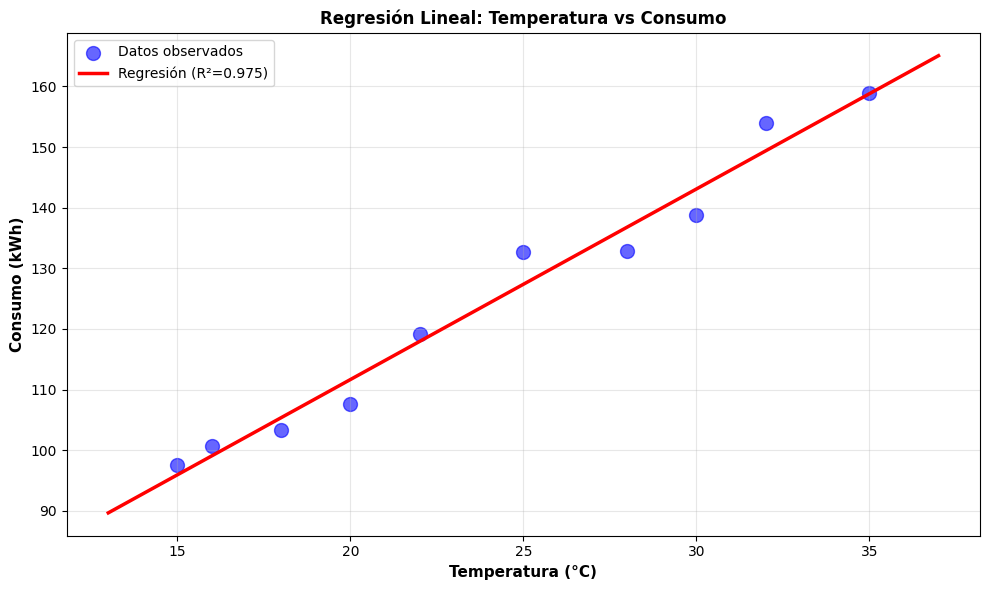

✓ Regresión completada


In [17]:
print('='*70)
print('Predicción de Demanda Eléctrica: Temperatura vs Consumo')
print('='*70)
print()

# Datos sintéticos
np.random.seed(42)
temperatura = np.array([15, 18, 22, 25, 28, 30, 32, 35, 20, 16])
consumo = 50 + 3 * temperatura + np.random.randn(10) * 5

print(f'{len(temperatura)} muestras de Temperatura vs Consumo')
print()

# Matriz X: [1, temperatura]
X = np.column_stack([np.ones(len(temperatura)), temperatura])
y = consumo

# Ecuaciones normales: β = (X^T X)^{-1} X^T y
XtX = X.T @ X
Xty = X.T @ y

beta = np.linalg.solve(XtX, Xty)
intercepto, pendiente = beta[0], beta[1]

print(f'Modelo: Consumo = {intercepto:.2f} + {pendiente:.2f} * Temperatura')
print()

# Predicciones
y_pred = X @ beta
residuos = y - y_pred

# Métricas
SSE = np.sum(residuos**2)
SST = np.sum((y - np.mean(y))**2)
R2 = 1 - (SSE / SST)
RMSE = np.sqrt(SSE / len(y))

print(f'Métricas:')
print(f'  R² = {R2:.4f}')
print(f'  RMSE = {RMSE:.4f}')
print()

# Gráfico
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(temperatura, consumo, s=100, alpha=0.6, color='blue', label='Datos observados')

x_linea = np.linspace(temperatura.min() - 2, temperatura.max() + 2, 100)
y_linea = intercepto + pendiente * x_linea
ax.plot(x_linea, y_linea, 'r-', linewidth=2.5, label=f'Regresión (R²={R2:.3f})')

ax.set_xlabel('Temperatura (°C)', fontsize=11, fontweight='bold')
ax.set_ylabel('Consumo (kWh)', fontsize=11, fontweight='bold')
ax.set_title('Regresión Lineal: Temperatura vs Consumo', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

print('✓ Regresión completada')

# 10. Resumen Integral

## Conceptos Clave

### 1. Interpretación Geométrica
- ℝ²: rectas, intersección de rectas
- ℝ³: planos, intersección de planos
- ℝⁿ: hiperplanos, intersección de hiperplanos

### 2. Clasificación de Sistemas (Rouché-Capelli)
- Solución única: rank(A) = rank([A|b]) = n
- Infinitas soluciones: rank(A) = rank([A|b]) < n
- Sin solución: rank(A) < rank([A|b])

### 3. Espacio Nulo y Solución General
- x = xₚ + xₕ, donde xₕ ∈ Null(A)
- dim(Null(A)) = n - rank(A)

### 4. Determinante e Invertibilidad
- det(A) ≠ 0 ⟺ A invertible ⟺ rank(A) = n
- Si invertible: x = A⁻¹b (solución única)

### 5. Métodos de Resolución
- Gauss-Jordan
- Regla de Cramer (matrices cuadradas)
- Inversión de matriz
- Métodos directos (NumPy)

### 6. Mínimos Cuadrados (Sistemas Sobredeterminados)
- Ecuaciones normales: (X^T X)β = X^T y
- Solución: β = (X^T X)⁻¹ X^T y
- Interpretación: proyección ortogonal

### 7. Aplicaciones
- Análisis de circuitos (LKC, LKV)
- Machine learning (regresión lineal)


---